## Macro Data


1. US Gross Domestic Product
2. Gross Domestic Product of Different Countries
3. Consumer Price Index
4. US Treasury Rate
5. Unemployment Rate
6. US Brent Crude
7. Gold ETF

In [1]:
# Import libraries
import truststore
truststore.inject_into_ssl()

import pandas as pd
import numpy as np
import yfinance as yf
from datetime import date
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

import os
import sys
sys.path.append("../../src")

# Import the get_fred_api from the financial_data package
# Add FRED_API_KEY to your .env file before you continue
from financial_data.data_fetchers import get_fred_api

# Dataframe to store the values as of today
macro_data = pd.DataFrame(index=['Value as of '+str(date.today())])

## US Gross Domestic Product

Gross Domestic Product (or GDP) is the monetary value of how much a country has produced in a year. It has a very significant impact on the financial market. The Federal Reserve Bank of St. Louis maintains an economic database, Federal Reserve Economic Data (FRED).

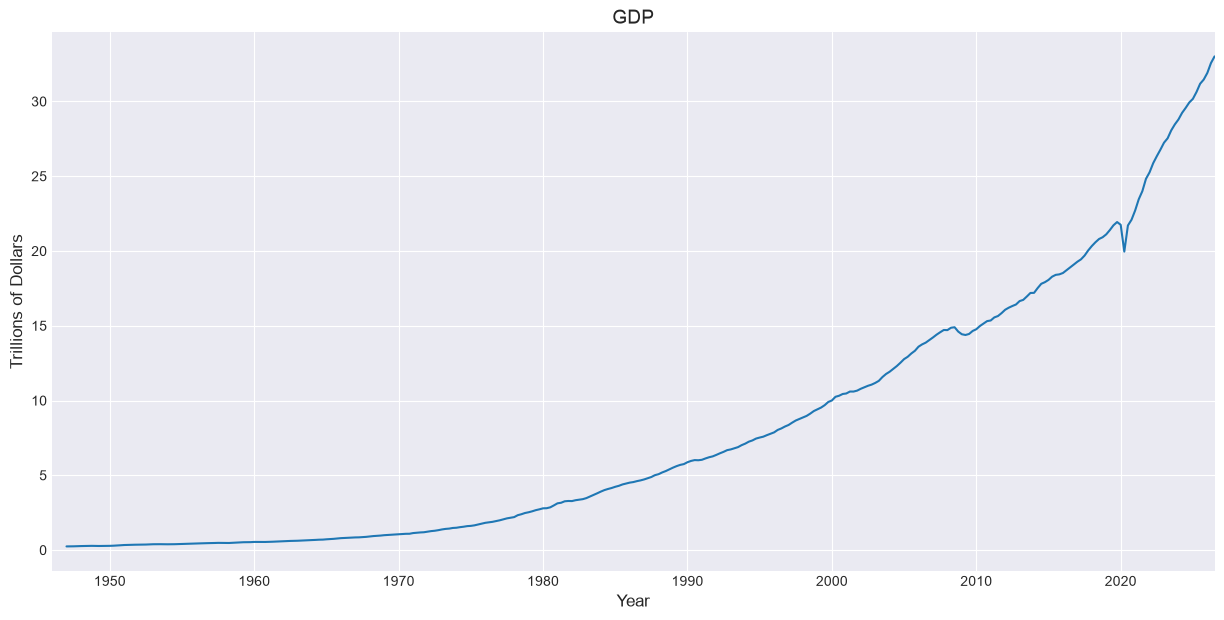

In [2]:
# importing library and API KEY
from fredapi import Fred
fred = Fred(api_key=get_fred_api())

# Get the US GDP
# Series ID for US GDP: GDP
gdp = fred.get_series('GDP')

# Data is fetched in Billions USD, divide by 1000 to convert into Trillions
gdp = gdp/1000

# Store the last value in 'macro_data'
macro_data["USD GDP"] = "{:.2f} trillions USD".format(gdp.iloc[-1])

# Plot the GDP
plt.figure(figsize = (15,7))
gdp.plot()

# Set the title and axis label
plt.title('GDP', fontsize = 14)
plt.xlabel('Year', fontsize = 12)
plt.ylabel('Trillions of Dollars', fontsize = 12)

# Show the plot
plt.show()


# Gross Domestic Product of Different Countries

You can download the GDP of different countries from the World Bank's database. Python comes with a powerful package wbgapi that provides access to the World Bank's database. GDP per capita data can be accessed by using the appropriate code.

Syntax:
import wbgapi as wb
wb.data.DataFrame([code], mrv, labels=True)

Parameters:
1. code: Series code, NY.GDP.MKTP.CD for GDP (current USD)
2. mrv: Most recent values
3. labels: Adds the country name to the dataframe when True

Returns: A pandas dataframe with country name and respective GDPs
You can find the complete list of code for different series by running the below code:
wb.series.info()

After you get the dataframe, apply the below operations on the resulting dataframe to get the list of countries with GDP in descending order:
1. Drop the missing values from the dataframe using the dropna() method.
2. Sort the values by NY.GDP.MKTP.CD column in descending order by using the sort_values() method.

In [3]:
import wbgapi as wb
ny_gdp = wb.data.DataFrame(['ny.gdp.mktp.cd'],
                           mrv=1,
                           labels=True).dropna().sort_values(by='NY.GDP.MKTP.CD',
                                                             ascending=False)[:10]

ny_gdp

,Country,NY.GDP.MKTP.CD
economy,,
WLD,World,1.183502e+14
HIC,High income,7.687805e+13
OED,OECD members,7.254327e+13
PST,Post-demographic dividend,6.737970e+13
IBT,IDA & IBRD total,4.625140e+13
IBD,IBRD only,4.305636e+13
LMY,Low & middle income,4.147860e+13
MIC,Middle income,4.083680e+13
EAS,East Asia & Pacific,3.365698e+13


You can filter the dataframe by the country code to check the GDP of a particular country. Let's plot the values for a few countries.

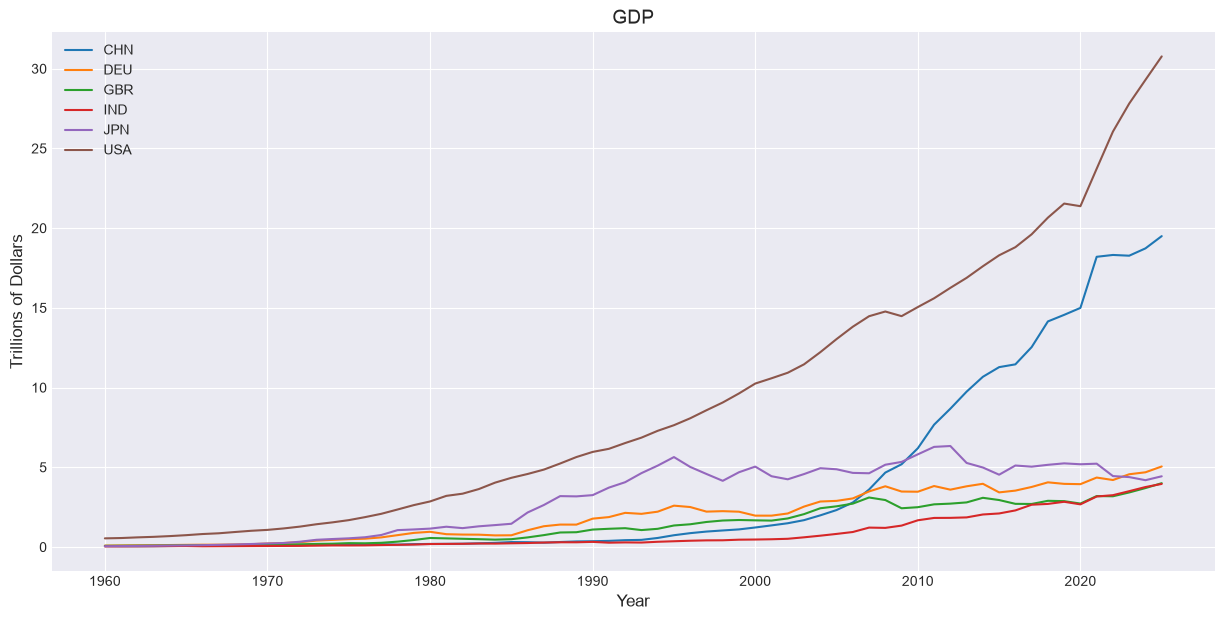

In [4]:
# GDP of 6 countries in Trillions USD
GDP = wb.data.DataFrame(['ny.gdp.mktp.cd'],
                        ['USA','CHN','JPN','DEU','IND','GBR']).T.dropna()/(10**12)

# Convert GDP data to numpy arrays
GDP_values = GDP.values
xtick = np.array([int(x[-4:]) for x in GDP.index.tolist()])

# Plot the GDP
fig, ax = plt.subplots(figsize=(15,7))

# Plot the series
for country_index in range(GDP_values.shape[1]):
    ax.plot(xtick, GDP_values[:, country_index], label=GDP.columns[country_index])

# Set the title and axis label
plt.title('GDP', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Trillions of Dollars', fontsize=12)
plt.legend()

# Show the plot
plt.show()

# Consumer Price Index
You can now use the get_series method of the Fred package to download the data by passing the appropriate series ID. The ID for CPI is CPIAUCSL. Plot the percentage change from the previous year to visualise the index.

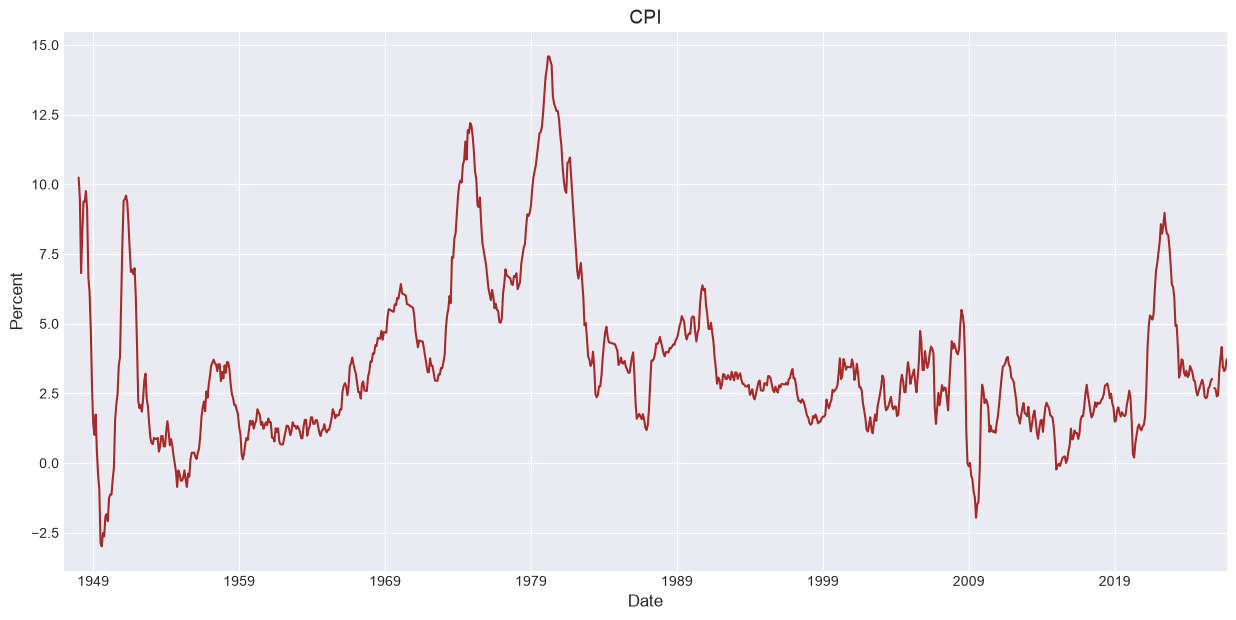

In [6]:
# Get the CPI
# Series ID for CPI: CPIAUCSL
cpi = fred.get_series('CPIAUCSL')
# Store the last value in 'macro_data'
macro_data['CPI'] = "{}%".format(round(cpi.pct_change(periods=12).iloc[-1],4)*100)

# Plot the CPI
plt.figure(figsize=(15,7))
(cpi.pct_change(periods=12)*100).plot(color="brown")
# Set the title and axis label
plt.title('CPI', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Percent', fontsize=12)
# Show the plot
plt.show()

# US Treasury

Change the series ID in get_series method of the Fred package appropriately to download the interest rate.
The IDs are as below:
- 3 Month US Treasury: DGS3MO
- 1 Year US Treasury: DGS1
- 10 Year US Treasury: DGS10

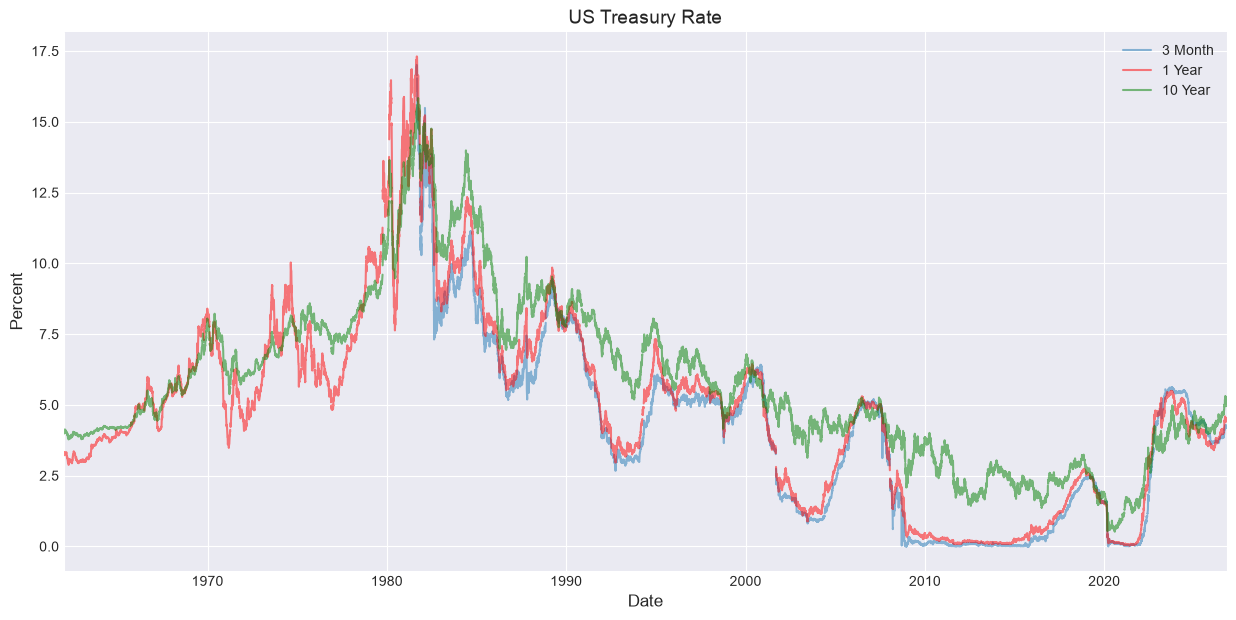

In [8]:
# Get the 3 month, 1 year and 10 year treasury rates
# Series ID for Treasury Rates: DGS3MO, DGS1, DGS10
treasury_3M = fred.get_series('DGS3MO')
treasury_1Y = fred.get_series('DGS1')
treasury_10Y = fred.get_series('DGS10')

# Store the last value in 'macro_data'
macro_data['3 Month US Treasury'] = "{}%".format(treasury_3M.iloc[-1])
macro_data['1 Year US Treasury'] = "{}%".format(treasury_1Y.iloc[-1])
macro_data['10 Year US Treasury'] = "{}%".format(treasury_10Y.iloc[-1])

# Plot the Treasury rates
plt.figure(figsize=(15,7))
treasury_3M.plot(label='3 Month', alpha=.5)
treasury_1Y.plot(label='1 Year', color="red", alpha=.5)
treasury_10Y.plot(label='10 Year', color="green", alpha=.5)

# Set the title and axis label
plt.title('US Treasury Rate', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Percent', fontsize=12)
plt.legend()

# Show the plot
plt.show()

# Unemployment Rate
Change the series ID in get_series method of the Fred package to UNRATE to download the unemployment rate.

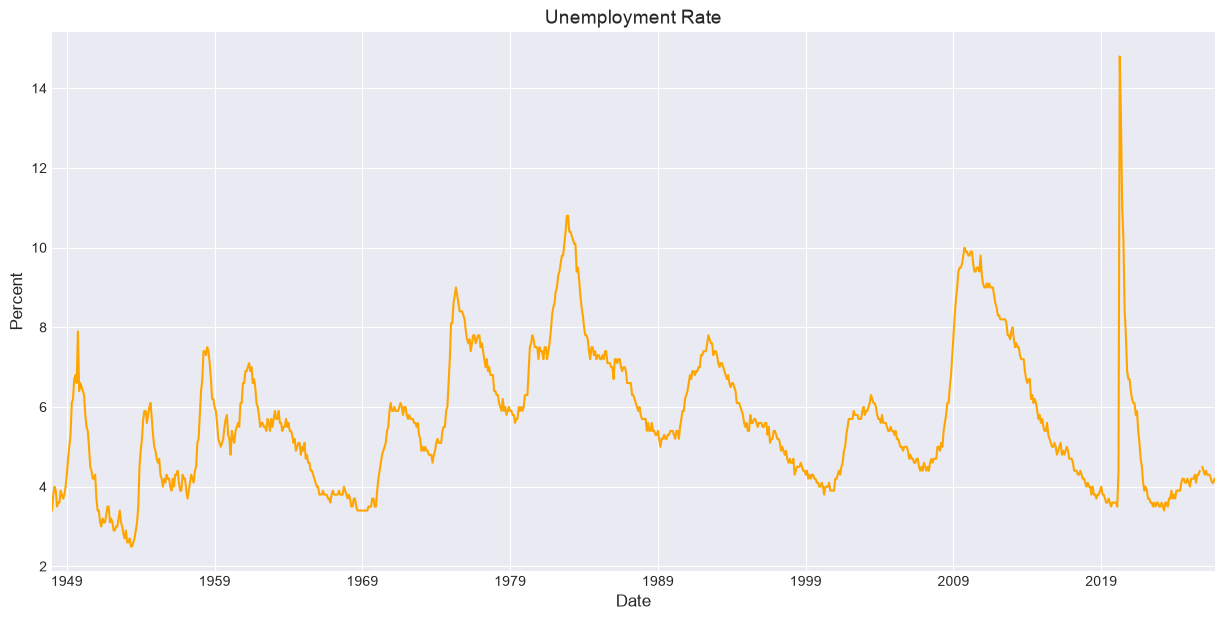

In [9]:
# Get the Unemployment Rate
# Series ID for Unemployment Rate: UNRATE
unemployment_rate = fred.get_series('UNRATE')

# Store the last value in 'macro_data'
macro_data['Unemployment Rate'] = "{}%".format(unemployment_rate.iloc[-1])

# Plot the unemployment rate
plt.figure(figsize=(15,7))
unemployment_rate.plot(color='orange')

# Set the title and axis label
plt.title('Unemployment Rate', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Percent', fontsize=12)
plt.legend()
plt.show()

# US Brent Crude Price

Change the series ID in get_series method of the Fred package to POILBREUSDM to download the US Brent Crude price.

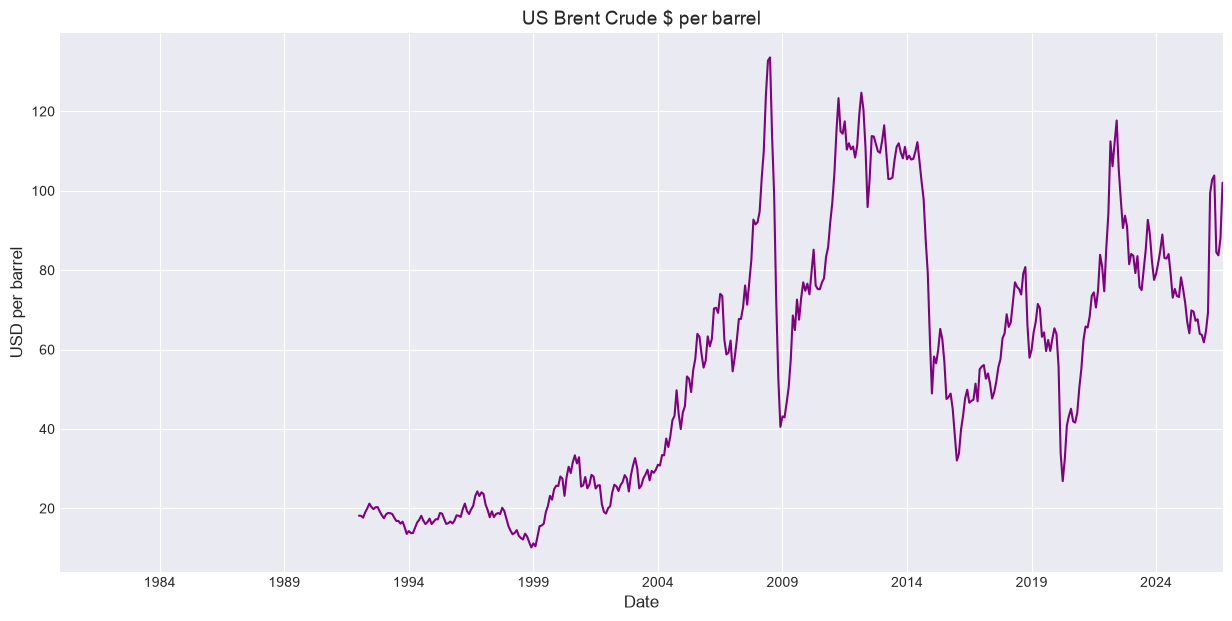

In [10]:
# Get the US Brent Crude price
# Series ID for US Brent Crude price: POILBREUSDM
us_brent_crude = fred.get_series('POILBREUSDM')

# Store the last value in 'macro_data'
macro_data['US Brent Crude'] = '{} USD per barrel'.format(us_brent_crude.iloc[-1])

# Plot the Crude price
plt.figure(figsize=(15,7))
us_brent_crude.plot(color='purple')

# Set the title and axis label
plt.title('US Brent Crude $ per barrel', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('USD per barrel', fontsize=12)
plt.legend()
plt.show()

# Gold ETF

Gold prices are also looked at by investors and traders and they usually invest in Gold ETFs (exchange-traded funds). SPDR Gold Shares ETF (GLD) is one such Gold ETF managed by State Street Global Advisors.

You can use the download method of the yfinance package to download the Gold price by passing GLD as the ticker.

[*********************100%***********************]  1 of 1 completed


<Figure size 1500x700 with 0 Axes>

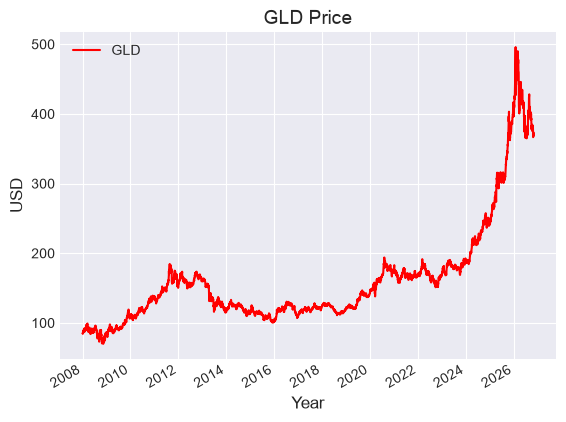

In [14]:
# Get the Gold price
gold_price = yf.download('GLD', '2008-01-01')['Close']

# Store the last value in 'macro_Data'
macro_data['GLD Price'] = "{} USD".format(gold_price.iloc[-1], 2)

# Plot the Gold Price
plt.figure(figsize=(15,7))
gold_price.plot(color='red')

# Set the title and axis label
plt.title('GLD Price', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('USD', fontsize=12)
plt.legend()
plt.show()



# Conclusion

You have visualised the various macro data for various time spans. The most recent value is stored in the dataframe macro_data. Let's print the data frame and check the recent values.

In [15]:
# Display the 'macro_data'
macro_data.astype(object).T

,Value as of 2026-10-30
USD GDP,33.01 trillions USD
CPI,3.7199999999999998%
3 Month US Treasury,4.18%
1 Year US Treasury,4.47%
10 Year US Treasury,5.05%
Unemployment Rate,4.2%
US Brent Crude,102.0180952380952 USD per barrel
GLD Price,Ticker\nGLD 368.570007\nName: 2026-10-29 00...


# The World Bank Data in Python

In [16]:
import pandas as pd
import world_bank_data as wb
pd.set_option('display.max_rows', 6)

### The list of topics is available with

In [17]:
wb.get_topics()

,value,sourceNote
id,,
1,Agriculture & Rural Development,For the 70 percent of the world's poor who liv...
2,Aid Effectiveness,Aid effectiveness is the impact that aid has i...
3,Economy & Growth,Economic growth is central to economic develop...
...,...,...
19,Climate Change,Climate change is expected to hit developing c...
20,External Debt,Debt statistics provide a detailed picture of ...
21,Trade,Trade is a key means to fight poverty and achi...


### Sources are returned by

In [18]:
wb.get_sources()

,lastupdated,name,code,description,url,dataavailability,metadataavailability,concepts
id,,,,,,,,
1,2021-08-18,Doing Business,DBS,,,Y,Y,3
2,2026-10-08,World Development Indicators,WDI,,,Y,Y,3
3,2026-09-25,Worldwide Governance Indicators,WGI,,,Y,Y,3
...,...,...,...,...,...,...,...,...
91,2026-10-06,PEFA_CRPFM,CRP,,,Y,Y,4
92,2025-03-28,Disability Data Hub (DDH),DDH,,,Y,Y,3
93,2026-07-21,FPN Datahub Archive,FPA,,,Y,Y,4


### And finally, the list of countries is accessible with

In [19]:
wb.get_countries()

,iso2Code,name,region,adminregion,incomeLevel,lendingType,capitalCity,longitude,latitude
id,,,,,,,,,
ABW,AW,Aruba,Latin America & Caribbean,,High income,Not classified,Oranjestad,-70.0167,12.5167
AFE,ZH,Africa Eastern and Southern,Aggregates,,Aggregates,Aggregates,,NaN,NaN
AFG,AF,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan","Middle East, North Africa, Afghanistan & Pakis...",Low income,IDA,Kabul,69.1761,34.5228
...,...,...,...,...,...,...,...,...,...
ZAF,ZA,South Africa,Sub-Saharan Africa,Sub-Saharan Africa (excluding high income),Upper middle income,IBRD,Pretoria,28.1871,-25.7460
ZMB,ZM,Zambia,Sub-Saharan Africa,Sub-Saharan Africa (excluding high income),Lower middle income,IDA,Lusaka,28.2937,-15.3982
ZWE,ZW,Zimbabwe,Sub-Saharan Africa,Sub-Saharan Africa (excluding high income),Lower middle income,Blend,Harare,31.0672,-17.8312


In [20]:
wb.get_regions()

,code,iso2code,name
id,,,
,AFE,ZH,Africa Eastern and Southern
,AFR,A9,Africa
,AFW,ZI,Africa Western and Central
...,...,...,...
,SXZ,A4,Sub-Saharan Africa excluding South Africa
,WLD,1W,World
,XZN,A5,Sub-Saharan Africa excluding South Africa and ...


In [21]:
wb.get_incomelevels()

,iso2code,value
id,,
HIC,XD,High income
INX,XY,Not classified
LIC,XM,Low income
...,...,...
LMY,XO,Low & middle income
MIC,XP,Middle income
UMC,XT,Upper middle income


### Get the list of indicators

This is done with the get_indicators function. You may query only the indicators for a specific source or topic as below. If you input no arguments, the get_indicator function will return the description of all the 16,000+ indicators.

In [22]:
wb.get_indicators(topic=3, source=2)  # topic and source id are from get_topics/get_sources

,name,unit,source,sourceNote,sourceOrganization,topics
id,,,,,,
BG.GSR.NFSV.GD.ZS,Trade in services (% of GDP),,World Development Indicators,Total trade in services includes services prov...,Balance of Payments Statistics Yearbook and da...,"Economy & Growth,Private Sector,Trade"
BM.GSR.CMCP.ZS,"Communications, computer, etc. (% of service i...",,World Development Indicators,"Communications, computer, information, and oth...",Balance of Payments Statistics Yearbook and da...,"Economy & Growth,Trade"
BM.GSR.FCTY.CD,"Primary income payments (BoP, current US$)",,World Development Indicators,Primary income payments refer to employee comp...,Balance of Payments Statistics Yearbook and da...,Economy & Growth
...,...,...,...,...,...,...
PA.NUS.ATLS,DEC alternative conversion factor (LCU per US$),,World Development Indicators,The DEC alternative conversion factor is the u...,"International Financial Statistics database, I...","Economy & Growth,Financial Sector"
PA.NUS.PPP,"PPP conversion factor, GDP (LCU per internatio...",,World Development Indicators,The purchasing power parity (PPP) conversion f...,"International Comparison Program (ICP), World ...",Economy & Growth
PA.NUS.PRVT.PP,"PPP conversion factor, households and NPISHs F...",,World Development Indicators,The purchasing power parity (PPP) conversion f...,"International Comparison Program (ICP), World ...",Economy & Growth


### Searching for one country or indicator

Use the functions search_countries, search_source, search_indicators. Or, if you want to search in a existing dataframe, simply use search.


In [23]:
wb.search_indicators('mathematics')

,name,unit,source,sourceNote,sourceOrganization,topics
id,,,,,,
2.0.cov.Math.pl_2.all,Coverage: Mathematics Proficiency Level 2,,LAC Equity Lab,The coverage rate is the childhood access rate...,LAC Equity Lab tabulations using PISA Data.,Poverty
2.0.cov.Math.pl_2.prv,"Coverage: Mathematics Proficiency Level 2, Pri...",,LAC Equity Lab,The coverage rate is the childhood access rate...,LAC Equity Lab tabulations using PISA Data.,Poverty
2.0.cov.Math.pl_2.pub,"Coverage: Mathematics Proficiency Level 2, Pub...",,LAC Equity Lab,The coverage rate is the childhood access rate...,LAC Equity Lab tabulations using PISA Data.,Poverty
...,...,...,...,...,...,...
UIS.READ.PRIMARY.NONNATIVE,Proportion of students at the end of primary e...,,Education Statistics,Percentage of children at the end of primary e...,UNESCO Institute for Statistics,
UIS.READ.PRIMARY.RURAL,Proportion of students at the end of primary e...,,Education Statistics,Percentage of children at the end of primary e...,UNESCO Institute for Statistics,
UIS.READ.PRIMARY.URBAN,Proportion of students at the end of primary e...,,Education Statistics,Percentage of children at the end of primary e...,UNESCO Institute for Statistics,


### Get the values of an indicator

The function get_series returns the value of a single indicator. The World Bank API accepts quite a few arguments, including:
- mrv, integer: one or more most recent values
- date, string: either one year, or two years separated with a colon, like '2010:2018'
- gapfill, string: 'Y' or 'N' (the default): forward fills missing values.

For instance, the call below returns the most recent estimate for the World Population:

In [24]:
wb.get_series('SP.POP.TOTL', mrv=1)

Country                      Series             Year
Africa Eastern and Southern  Population, total  2025    788844284.0
Africa Western and Central   Population, total  2025    532809933.0
Arab World                   Population, total  2025    503356133.0
                                                           ...     
Yemen, Rep.                  Population, total  2025     41773878.0
Zambia                       Population, total  2025     21913874.0
Zimbabwe                     Population, total  2025     16950795.0
Name: SP.POP.TOTL, Length: 266, dtype: float64

The result above has a 3-dimensional index. Use the argument simplify_index to ignore the dimensions that take a single value (here: year and series). Also, use the argument id_or_value='id' if you prefer your data to be indexed by the codes rather than labels:

In [25]:
wb.get_series('SP.POP.TOTL', date='2016', id_or_value='id', simplify_index=True)

Country
AFE    623369401.0
AFW    428797338.0
ARB    419808341.0
          ...     
YEM     32109010.0
ZMB     16914423.0
ZWE     14600294.0
Name: SP.POP.TOTL, Length: 266, dtype: float64